# Lazo de Nb: cómo medir el filtro criogénico y qué resistencia de carga usar

**Problema.** El filtro criogénico no se puede medir directo: su salida termina en
el portamuestras, adentro del criostato, y ahí no llegan las puntas del analizador.

**Propuesta.** En el portamuestras se unen dos canales (A y B) con alambre de Nb:
A+ con B+ y A− con B−. Entre + y −, en el lugar donde iría la juntura, se pone una
resistencia de carga $R_L$. El generador entra por A y el analizador mide por B,
así que las dos puntas quedan afuera del criostato. La señal recorre
**filtro A → lazo de Nb → filtro B**.

En este notebook se simula ese lazo para:
1. ver cómo queda la transferencia según $R_L$,
2. ver cuánto molesta que el Nb no sea superconductor (si se mide en caliente),
3. elegir una $R_L$ razonable.

```
 Generador (1 V, 50 Ω)            CANAL A                     portamuestras
   ┌──50Ω──┐  Ai+ ─22Ω─ A1+ ─22Ω─ A2+ ─22Ω─ Ao+ ──R_nb──┐
   │  1 V  │                 │47nF     │47nF            │
   └───────┘  Ai− ─22Ω─ A1− ─22Ω─ A2− ─22Ω─ Ao− ──R_nb──┤
                                                        R_L
 Analizador (50 Ω)                CANAL B                 │
   ┌─50Ω─┐    Bi+ ─22Ω─ B1+ ─22Ω─ B2+ ─22Ω─ Bo+ ─────────┘ (Ao+ ↔ Bo+ por el Nb)
   └─────┘    Bi− ─22Ω─ B1− ─22Ω─ B2− ─22Ω─ Bo−            (Ao− ↔ Bo− por el Nb)
```
Los capacitores van **entre líneas** (+ y −), no a tierra. Generador y analizador
están flotantes (modo diferencial).

## 1. Librerías
- `numpy`: álgebra con números complejos (impedancias) y resolver sistemas lineales.
- `scipy.optimize.brentq`: buscar la frecuencia exacta donde la curva cae 3 dB.
- `matplotlib`: gráficos. `pandas`: la tabla final.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import brentq

## 2. Parámetros
Todo lo que se puede querer cambiar está acá arriba. En particular el largo `L_nb` y
el diámetro `d_nb` del alambre de Nb.

In [2]:
# --- Filtro criogénico (cada canal, cada línea) ---
R_cry = 22.0        # Ω, cada una de las 3 resistencias en serie por línea
C_cry = 47e-9       # F, cada uno de los 2 capacitores entre + y −

# --- Instrumentos ---
R_gen = 50.0        # Ω, resistencia interna del generador
V_gen = 1.0         # V, amplitud del generador (la transferencia no depende de esto)
R_an = 50.0         # Ω, impedancia de entrada del analizador

# --- Alambre de Nb (EDITABLE) ---
rho_nb = 15e-8      # Ω·m  (= 15 µΩ·cm, Nb a temperatura ambiente)
L_nb = 2e-2         # m    (2 cm)
d_nb = 50e-6        # m    (50 µm)

# --- Barrido en frecuencia ---
f = np.logspace(1, 7, 601)   # de 10 Hz a 10 MHz, 100 puntos por década

# --- Cargas a comparar ---
R_L_lista = [10, 50, 100, 500, 1000, 10000]   # Ω

## 3. Resistencia del Nb
- **En frío** el Nb es superconductor ($T_c \approx 9{,}2$ K), así que $R_{nb} = 0$.
- **En caliente** es un metal normal: $R_{nb} = \rho L / A$, con sección
  $A = \pi d^2/4$.

In [3]:
A_nb = np.pi * d_nb**2 / 4          # sección del alambre (m²)
R_nb_caliente = rho_nb * L_nb / A_nb
R_nb_frio = 0.0

print(f"R_nb en caliente = {R_nb_caliente:.3f} Ω por alambre")

R_nb en caliente = 1.528 Ω por alambre


## 4. El modelo: análisis nodal (Kirchhoff)

**Idea.** Cada punto del circuito donde se juntan componentes es un *nodo* con un
voltaje (complejo) desconocido. La ley de corrientes de Kirchhoff dice que en cada
nodo la suma de corrientes que salen es cero. Si escribimos cada componente como
una **admitancia** $Y = 1/Z$ ($Y_R = 1/R$, $Y_C = j\omega C$), eso queda como un
sistema lineal

$$\mathbf{Y}\,\mathbf{V} = \mathbf{I}$$

donde $\mathbf{Y}$ es la *matriz de admitancias*, $\mathbf{V}$ los voltajes de los
nodos e $\mathbf{I}$ las corrientes que inyectan las fuentes. Se resuelve una vez
por frecuencia.

**Cómo se arma $\mathbf{Y}$.** Un componente de admitancia $y$ entre los nodos $a$ y
$b$ suma $+y$ en $Y_{aa}$ y $Y_{bb}$, y $-y$ en $Y_{ab}$ y $Y_{ba}$. Se repite para
todos los componentes y listo.

**El generador.** Una fuente de 1 V con 50 Ω en serie es equivalente
(Norton) a una fuente de corriente $V/R$ en paralelo con los 50 Ω. Así entra fácil
en el sistema: inyecta $+V/R$ en Ai+ y saca lo mismo de Ai−.

**¿Y la tierra?** Como todo está flotante no hay tierra. Pero los voltajes siempre se
definen respecto de algún punto, así que se elige un nodo cualquiera como
referencia (Bi−, con $V=0$) y se lo saca del sistema. Si no se hace esto,
$\mathbf{Y}$ es singular (no se puede invertir), porque sumarle la misma constante
a todos los voltajes no cambia ninguna corriente.

**Nb superconductor.** $R_{nb} = 0$ daría admitancia infinita. En vez de eso,
Ao+ y Bo+ se tratan directamente como **el mismo nodo** (lo mismo con Ao− y
Bo−), que es lo que físicamente es un cable sin resistencia.

In [4]:
def transferencia_lazo(frec, R_L, R_nb):
    '''Devuelve H = 2·V_analizador/V_generador (complejo) a la frecuencia frec (Hz).

    Se arma el circuito completo, línea por línea, sin simplificar.
    '''
    w = 2 * np.pi * frec

    # Si el Nb es superconductor, Bo± son el mismo nodo que Ao±.
    def nombre(nodo):
        if R_nb == 0 and nodo.startswith("Bo"):
            return "Ao" + nodo[2:]
        return nodo

    nodos = []          # lista de nombres de nodos, en el orden en que aparecen
    componentes = []    # lista de (nodo_a, nodo_b, admitancia)

    def indice(nodo):
        nodo = nombre(nodo)
        if nodo not in nodos:
            nodos.append(nodo)
        return nodos.index(nodo)

    def agregar(a, b, Z):
        componentes.append((indice(a), indice(b), 1 / Z))

    Z_C = 1 / (1j * w * C_cry)   # impedancia de cada capacitor

    # --- Los dos filtros criogénicos (A y B), iguales ---
    # 'i' = lado de afuera (instrumento), '1','2' = nodos internos, 'o' = portamuestras
    for canal in ["A", "B"]:
        for linea in ["+", "-"]:
            agregar(f"{canal}i{linea}", f"{canal}1{linea}", R_cry)
            agregar(f"{canal}1{linea}", f"{canal}2{linea}", R_cry)
            agregar(f"{canal}2{linea}", f"{canal}o{linea}", R_cry)
        # capacitores ENTRE líneas, después de la 1ª y de la 2ª resistencia
        agregar(f"{canal}1+", f"{canal}1-", Z_C)
        agregar(f"{canal}2+", f"{canal}2-", Z_C)

    # --- Alambres de Nb (solo si tienen resistencia; si no, ya se unieron los nodos) ---
    if R_nb > 0:
        agregar("Ao+", "Bo+", R_nb)
        agregar("Ao-", "Bo-", R_nb)

    # --- Carga en el lugar de la juntura ---
    agregar("Ao+", "Ao-", R_L)

    # --- Instrumentos ---
    agregar("Ai+", "Ai-", R_gen)   # resistencia interna del generador (Norton)
    agregar("Bi+", "Bi-", R_an)    # entrada del analizador

    # --- Matriz de admitancias ---
    N = len(nodos)
    Y = np.zeros((N, N), dtype=complex)
    for a, b, y in componentes:
        Y[a, a] += y
        Y[b, b] += y
        Y[a, b] -= y
        Y[b, a] -= y

    # --- Corrientes inyectadas (generador como fuente de corriente Norton) ---
    I = np.zeros(N, dtype=complex)
    I[indice("Ai+")] += V_gen / R_gen
    I[indice("Ai-")] -= V_gen / R_gen

    # --- Nodo de referencia: Bi− = 0 V. Se saca su fila y columna y se resuelve ---
    ref = indice("Bi-")
    resto = [k for k in range(N) if k != ref]
    V = np.zeros(N, dtype=complex)
    V[resto] = np.linalg.solve(Y[np.ix_(resto, resto)], I[resto])

    V_analizador = V[indice("Bi+")] - V[indice("Bi-")]
    return 2 * V_analizador / V_gen

### ¿Por qué el factor 2 en $H$?
Si el generador (50 Ω) se conecta **directo** al analizador (50 Ω), el analizador
ve $V_{gen}/2$ (divisor de tensión). Esa es la medición de referencia. Con el
factor 2, $H = 1$ (0 dB) quiere decir "lo mismo que la referencia", y en dB
$H = P_{lazo} - P_{referencia}$, que es justo lo que se mide restando dos trazas
del analizador.

### Frecuencia de corte
$f_c$ es donde $|H|$ cae 3 dB respecto de su valor a baja frecuencia. Se usa la
definición clásica: amplitud dividida por $\sqrt2$, o sea
$20\log_{10}\sqrt2 = 3{,}0103$ dB. Usar 3,000 dB exactos corre $f_c$ ~0,2 %
hacia abajo, que es poco pero alcanza para no coincidir con los valores de
referencia.

Para encontrarla se usa `brentq`: un método que busca dónde una función cruza
cero. La función es (caída en dB) − 3,01, y se busca en $\log_{10} f$ porque la
curva varía en escala logarítmica.

In [5]:
CAIDA_3dB = 20 * np.log10(np.sqrt(2))   # = 3.0103 dB
F_BAJA = 1.0                            # Hz, frecuencia "de continua" para el nivel de referencia

def H_dB(frecs, R_L, R_nb):
    '''|H| en dB para un array de frecuencias.'''
    return np.array([20 * np.log10(abs(transferencia_lazo(fr, R_L, R_nb))) for fr in frecs])

def nivel_baja_frecuencia(R_L, R_nb):
    '''|H| en dB a baja frecuencia (donde los capacitores son circuitos abiertos).'''
    return 20 * np.log10(abs(transferencia_lazo(F_BAJA, R_L, R_nb)))

def frecuencia_corte(R_L, R_nb):
    '''f_c (Hz): donde |H| cae 3,01 dB respecto del nivel a baja frecuencia.'''
    nivel0 = nivel_baja_frecuencia(R_L, R_nb)
    def g(log_f):
        return 20 * np.log10(abs(transferencia_lazo(10**log_f, R_L, R_nb))) - nivel0 + CAIDA_3dB
    return 10 ** brentq(g, 0, 8)   # busca entre 1 Hz y 100 MHz

## 5. Validación

Antes de creerle al modelo se compara contra valores conocidos.

**a) Un solo canal, excitación diferencial ideal, salida abierta.** Es otro circuito
(sin generador real, sin lazo), así que se resuelve aparte. Por simetría, un
capacitor $C$ entre + y − equivale a un capacitor $2C$ de cada línea a un punto
medio que no se mueve (la "tierra virtual" del modo diferencial). Queda una
escalera RC de 2 etapas por línea, $R$ – $2C$ – $R$ – $2C$ – $R$, con la última $R$
sin corriente porque la salida está abierta.

In [6]:
def canal_solo_abierto(frec):
    '''V_salida/V_entrada de un canal, excitación diferencial ideal, salida abierta.'''
    w = 2 * np.pi * frec
    Z_2C = 1 / (1j * w * 2 * C_cry)          # capacitor equivalente por línea
    # 2ª etapa: divisor R / 2C (la R final no lleva corriente)
    etapa2 = Z_2C / (R_cry + Z_2C)
    # impedancia que ve el nodo 1: 2C en paralelo con (R + 2C)
    Z1 = 1 / (1 / Z_2C + 1 / (R_cry + Z_2C))
    etapa1 = Z1 / (R_cry + Z1)
    return etapa1 * etapa2

fc_canal = 10 ** brentq(lambda lf: 20*np.log10(abs(canal_solo_abierto(10**lf))) + CAIDA_3dB, 0, 8)

# (descripción, calculado, esperado)
chequeos = [
    ("Canal solo, salida abierta: f_c (kHz)", fc_canal / 1e3,                                  28.80),
    ("R_nb caliente (Ω)",                     R_nb_caliente,                                   1.53),
    ("Lazo, Nb frío, R_L = 10 Ω: f_c (kHz)",  frecuencia_corte(10, R_nb_frio) / 1e3,           29.97),
    ("Lazo, Nb frío, R_L = 50 Ω: f_c (kHz)",  frecuencia_corte(50, R_nb_frio) / 1e3,           23.49),
    ("Lazo, Nb frío, R_L = 10 kΩ: f_c (kHz)", frecuencia_corte(1e4, R_nb_frio) / 1e3,          14.69),
    ("Lazo, Nb caliente, R_L = 50 Ω: f_c (kHz)", frecuencia_corte(50, R_nb_caliente) / 1e3,    23.29),
]
for desc, calc, esp in chequeos:
    ok = "OK" if round(calc, 2) == esp else "NO COINCIDE"   # coincide a 2 decimales
    print(f"{desc:45s} calculado = {calc:8.3f}   esperado = {esp:6.2f}   {ok}")

Canal solo, salida abierta: f_c (kHz)         calculado =   28.802   esperado =  28.80   OK
R_nb caliente (Ω)                             calculado =    1.528   esperado =   1.53   OK
Lazo, Nb frío, R_L = 10 Ω: f_c (kHz)          calculado =   29.968   esperado =  29.97   OK
Lazo, Nb frío, R_L = 50 Ω: f_c (kHz)          calculado =   23.487   esperado =  23.49   OK
Lazo, Nb frío, R_L = 10 kΩ: f_c (kHz)         calculado =   14.692   esperado =  14.69   OK
Lazo, Nb caliente, R_L = 50 Ω: f_c (kHz)      calculado =   23.294   esperado =  23.29   OK


## 6. Transferencia del lazo para distintas $R_L$ (Nb en frío)
Cada curva tiene su $f_c$ marcada con un punto. Todas las curvas salen del mismo
modelo; lo único que cambia es $R_L$.

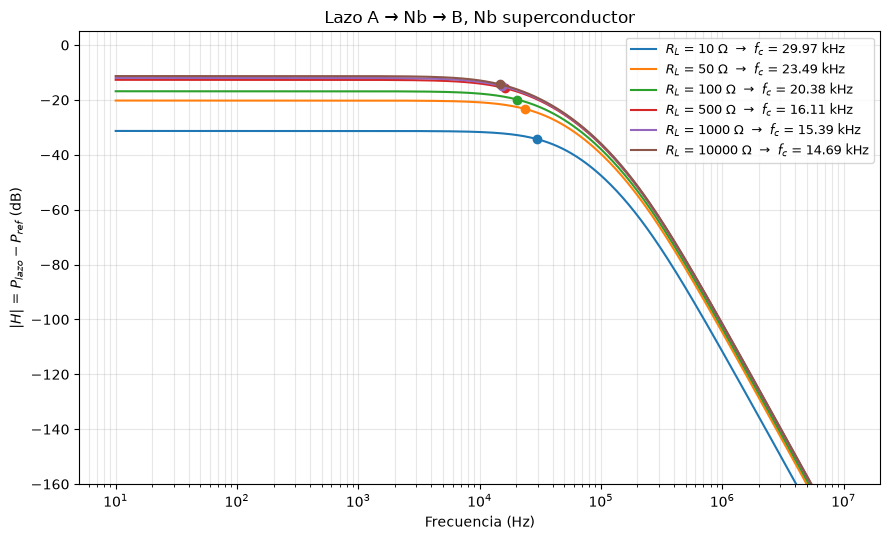

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for R_L in R_L_lista:
    curva = H_dB(f, R_L, R_nb_frio)
    fc = frecuencia_corte(R_L, R_nb_frio)
    nivel_fc = nivel_baja_frecuencia(R_L, R_nb_frio) - CAIDA_3dB
    linea, = ax.semilogx(f, curva, label=f"$R_L$ = {R_L:g} Ω  →  $f_c$ = {fc/1e3:.2f} kHz")
    ax.plot(fc, nivel_fc, "o", color=linea.get_color())

ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("$|H|$ = $P_{lazo} - P_{ref}$ (dB)")
ax.set_title("Lazo A → Nb → B, Nb superconductor")
ax.set_ylim(-160, 5)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 7. $f_c$ en función de $R_L$: Nb en frío vs. en caliente

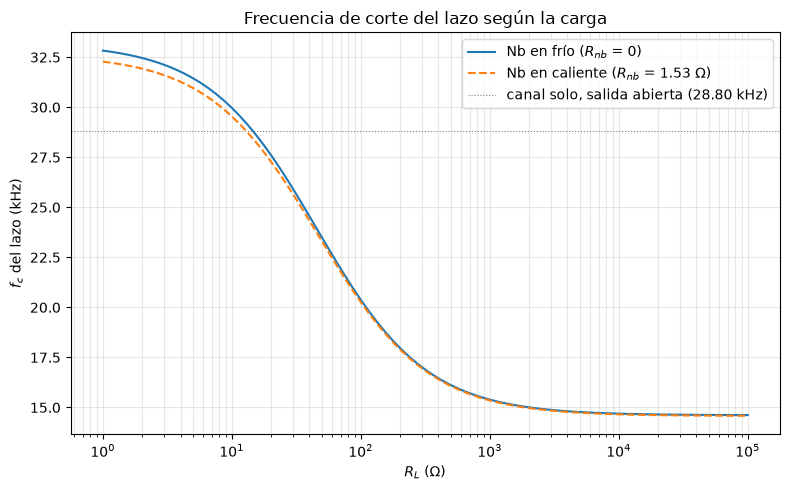

In [8]:
R_L_barrido = np.logspace(0, 5, 81)    # de 1 Ω a 100 kΩ
fc_frio = np.array([frecuencia_corte(R, R_nb_frio) for R in R_L_barrido])
fc_caliente = np.array([frecuencia_corte(R, R_nb_caliente) for R in R_L_barrido])

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogx(R_L_barrido, fc_frio / 1e3, label="Nb en frío ($R_{nb}$ = 0)")
ax.semilogx(R_L_barrido, fc_caliente / 1e3, "--", label=f"Nb en caliente ($R_{{nb}}$ = {R_nb_caliente:.2f} Ω)")
ax.axhline(fc_canal / 1e3, color="gray", lw=0.8, ls=":", label=f"canal solo, salida abierta ({fc_canal/1e3:.2f} kHz)")
ax.set_xlabel("$R_L$ (Ω)")
ax.set_ylabel("$f_c$ del lazo (kHz)")
ax.set_title("Frecuencia de corte del lazo según la carga")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Tabla para elegir $R_L$

Columnas:
- **f_c frío / caliente**: frecuencia de corte del lazo con el Nb superconductor o normal.
- **Δf_c por Nb**: cuánto cambia $f_c$ si se mide en caliente (cuánto "miente" una
  medición a temperatura ambiente sobre lo que pasa en frío).
- **Δf_c si R_L +10 %**: sensibilidad a la tolerancia de la resistencia (Nb en frío).
  Si es grande, cualquier error en $R_L$ se traslada a $f_c$.
- **Nivel a baja f**: cuánta señal llega al analizador en la parte plana (Nb en frío).
  Muy negativo = poca señal, peor relación señal/ruido.

In [9]:
filas = []
for R_L in R_L_lista:
    fc_f = frecuencia_corte(R_L, R_nb_frio)
    fc_c = frecuencia_corte(R_L, R_nb_caliente)
    fc_10 = frecuencia_corte(1.1 * R_L, R_nb_frio)
    filas.append({
        "R_L (Ω)": R_L,
        "f_c frío (kHz)": fc_f / 1e3,
        "f_c caliente (kHz)": fc_c / 1e3,
        "Δf_c por Nb (%)": 100 * (fc_c - fc_f) / fc_f,
        "Δf_c si R_L +10 % (%)": 100 * (fc_10 - fc_f) / fc_f,
        "Nivel a baja f (dB)": nivel_baja_frecuencia(R_L, R_nb_frio),
    })

tabla = pd.DataFrame(filas).set_index("R_L (Ω)")
tabla.round(2)

,f_c frío (kHz),f_c caliente (kHz),Δf_c por Nb (%),Δf_c si R_L +10 % (%),Nivel a baja f (dB)
R_L (Ω),,,,,
10,29.97,29.54,-1.42,-0.89,-31.31
50,23.49,23.29,-0.82,-1.92,-20.23
100,20.38,20.26,-0.57,-1.86,-16.84
500,16.11,16.07,-0.30,-0.79,-12.67
1000,15.39,15.35,-0.27,-0.44,-11.98
10000,14.69,14.66,-0.24,-0.05,-11.30


## 9. Cómo leer los resultados

- **$R_L$ chica** (≲ 20 Ω): la carga casi cortocircuita la salida del canal A, y
  los dos filtros quedan "separados" por ella. La $f_c$ del lazo sube (hasta
  ~33 kHz, por encima de los 28,8 kHz de un canal solo). Pero llega muy poca señal
  (−31 dB con 10 Ω), y como $R_L$ es comparable con el Nb caliente, medir en
  caliente se aparta más de lo que pasa en frío (−1,4 % en $f_c$ con 10 Ω).
- **$R_L$ grande** (≳ 1 kΩ): el lazo se comporta como los dos filtros en cascada
  sin carga ($f_c \to$ ~14,7 kHz). $f_c$ casi no depende de $R_L$ (−0,05 % por un
  +10 % de $R_L$ con 10 kΩ), el Nb caliente casi no influye (−0,24 %) y hay más
  señal (−11,3 dB).
- **Zona intermedia** (~20 Ω a ~500 Ω): es donde $f_c$ cambia más rápido con $R_L$
  (casi −2 % por un +10 % de $R_L$ alrededor de 50–100 Ω), así que ahí hay que
  conocer muy bien el valor real de la resistencia.

**Ojo:** lo que se mide es la transferencia del **lazo completo** (dos filtros +
carga), no la de un filtro solo. Para comparar hay que usar esta simulación con la
$R_L$ que realmente se ponga.